# 02 · The bus timetable (GTFS) and stop-name matching

**Goal:** (1) read the timetable files and turn them into **route patterns** (the ordered list of stops of every route),
(2) count how many **buses are scheduled** on every stretch of road in every hour, and
(3) link the **stop names typed on tickets** to real stops.

**Why we need this:** a ticket says "Mahipal Pur -> Kalkaji" but not which stop numbers those are. To know which *stretches* a passenger travelled through,
we must place both names on the route's stop list.

**GTFS in one minute:** a folder of text (CSV) files.

| File | Contains |
|---|---|
| `stops.txt` | every stop: id, name, latitude, longitude |
| `routes.txt` | every route (in Delhi's file `8UP` and `8DOWN` are two separate routes) |
| `trips.txt` | every scheduled run of a bus on a route |
| `stop_times.txt` | for each trip: which stops, in what order, at what time |

In [1]:
# --- Setup: run this cell first ---------------------------------------------------------------
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # lets the notebook find config.py and the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import db

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 140)

print("Data mode:", config.MODE.upper(), "| database:", config.DB_NAME if config.USE_MYSQL else "SQLite file")

from src import gtfs

Data mode: REAL | database: SQLite file


## 1. Build route patterns

In [2]:
patterns, hourly, trip_starts = gtfs.build_patterns()      # see src/gtfs.py - readable pandas, ~20 seconds
print(f"{patterns.route_n.nunique():,} route-directions | {patterns.stop_id.nunique():,} distinct stops | {len(trip_starts):,} scheduled trips per day")
patterns.head(8)

2,574 route-directions | 6,825 distinct stops | 80,357 scheduled trips per day


,route,route_id,dir,n_trips,idx,stop_id,stop_name,lat,lon,cum_sec,route_n,name_n
0,102ADOWN,1,0,16,0,1,Rohini Sec 22 Terminal,28.717971,77.063900,0,102ADOWN,rohini sector 22 terminal
1,102ADOWN,1,0,16,1,2,Lakhhi Ram Park,28.713533,77.060302,120,102ADOWN,lakhhi ram park
2,102ADOWN,1,0,16,2,4470,Aman Vihar,28.711313,77.063228,196,102ADOWN,aman vihar
3,102ADOWN,1,0,16,3,4087,Shiv Chowk Rohini Sec 20,28.709669,77.067154,281,102ADOWN,shiv chowk rohini sector 20
4,102ADOWN,1,0,16,4,4086,Rohini Sec 20 / 21 Pocket 9,28.713825,77.070708,396,102ADOWN,rohini sector 20 21 pocket 9
5,102ADOWN,1,0,16,5,3,Rohini Sec21,28.718700,77.069600,506,102ADOWN,rohini sec21
6,102ADOWN,1,0,16,6,4,Rohini Sec 20/21/22 Crossing,28.720084,77.068825,541,102ADOWN,rohini sector 20 21 22 crossing
7,102ADOWN,1,0,16,7,5,Police Station Begumpur,28.723037,77.071410,623,102ADOWN,police station begumpur


`idx` is the stop number along the route (0, 1, 2, ...). `cum_sec` is the scheduled time in seconds since the route's first stop.
One route can have several trip variants (short runs, different endings); we keep the **most common** one as the route's pattern.

count    2574.0
mean       31.2
std        20.5
min         2.0
25%        13.0
50%        29.0
75%        47.0
max       183.0


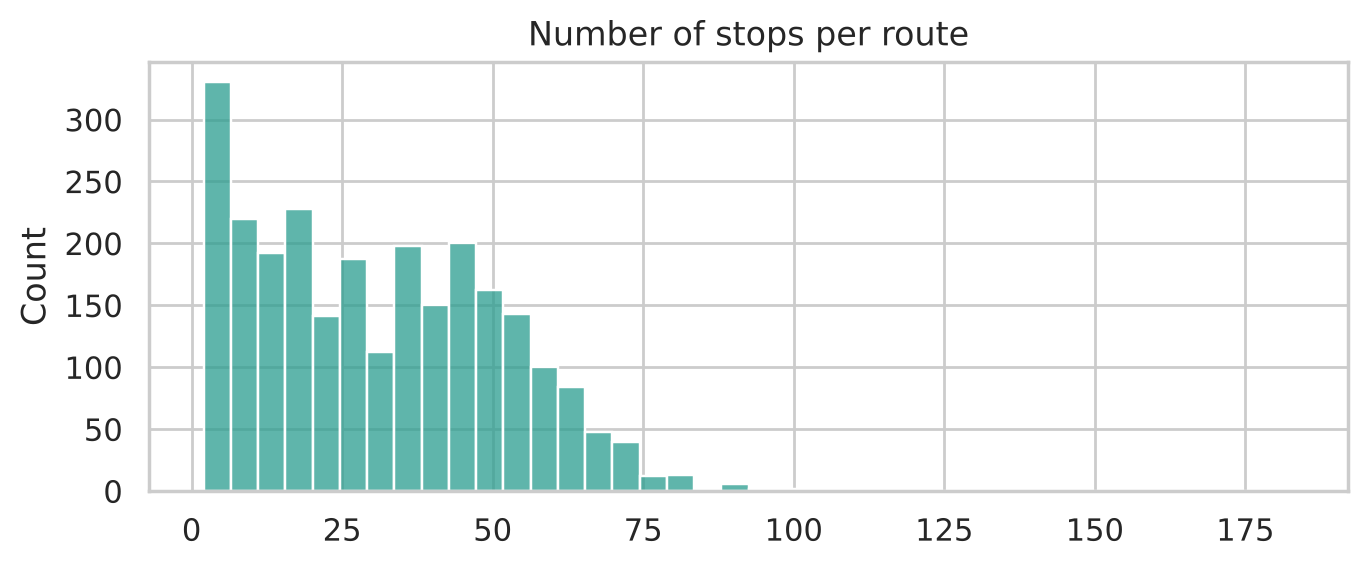

In [3]:
stops_per_route = patterns.groupby("route_n").size()
print(stops_per_route.describe().round(1).to_string())
plt.figure(figsize=(7, 3)); sns.histplot(stops_per_route, bins=40, color="#2a9d8f"); plt.title("Number of stops per route"); plt.tight_layout(); plt.show()

### A look at one route on a map-like plot

Busiest route by tickets: 717AUP -> 52 stops, 92 min end to end


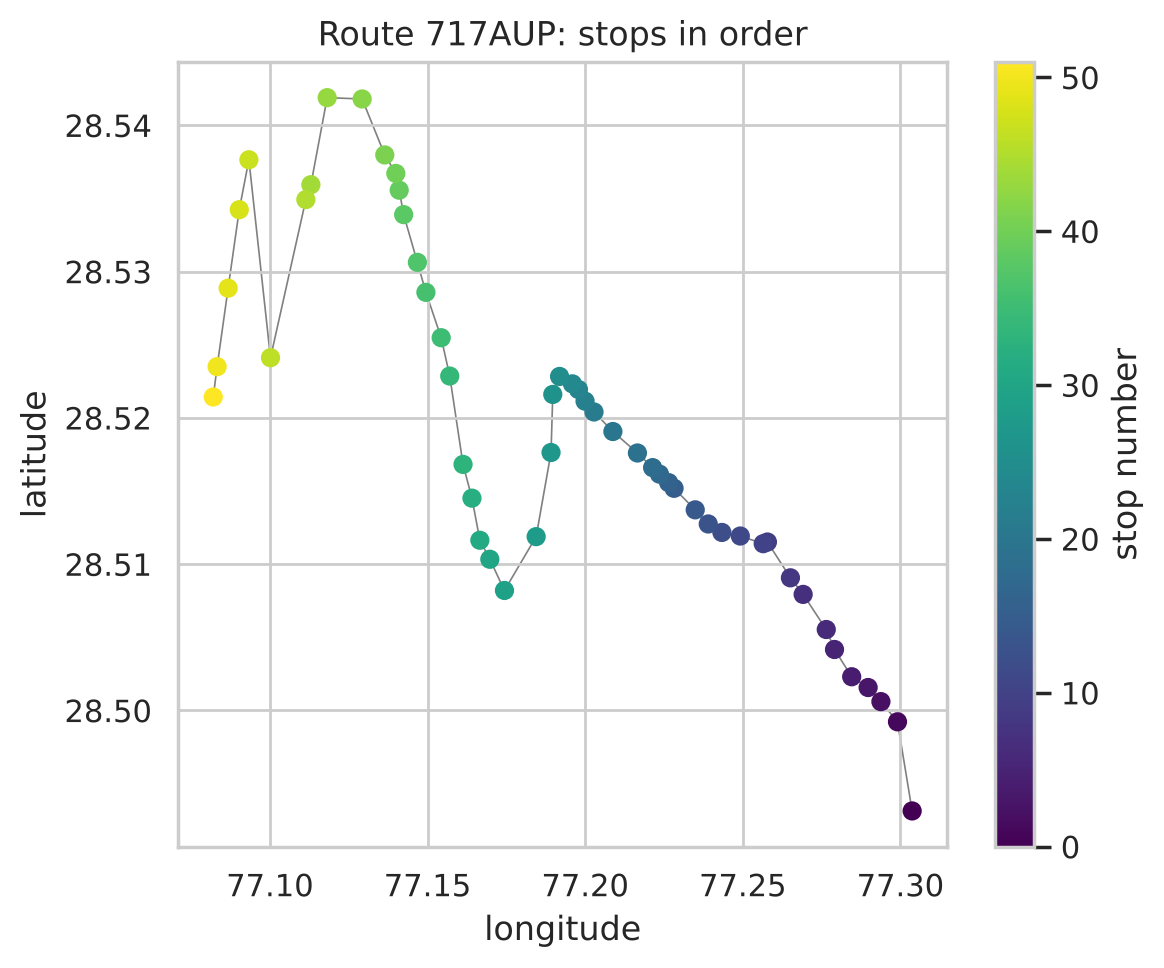

,idx,stop_name,lat,lon,cum_sec
31897,0,Badarpur Border (T),28.493130,77.303727,0
31898,1,Badarpur M B Road / Rajiv Gandhi Stadium,28.499224,77.299076,162
31899,2,Pul Pehladpur ( BadarPur),28.500603,77.293822,270
31900,3,Surajkund Crossing,28.501567,77.289765,352
31901,4,Lal Kuan,28.502304,77.284550,455
31902,5,Prem Nagar (TUGLQABAD ROAD),28.504167,77.279100,570
31903,6,Tuglaqabad MB Road / Okhla more,28.505533,77.276483,629
31904,7,Kaya Maya Hospital,28.507933,77.269150,782
31905,8,Tughalqabad Village,28.509067,77.265117,865
31906,9,Tuglakabad Fort,28.511514,77.257817,1018


In [4]:
top_route = db.query("SELECT route_raw FROM tickets GROUP BY route_raw ORDER BY COUNT(*) DESC LIMIT 1", db.get_engine()).route_raw[0]
r = patterns[patterns.route == top_route]
print("Busiest route by tickets:", top_route, "->", len(r), "stops,", f"{r.cum_sec.max()/60:.0f} min end to end")
plt.figure(figsize=(6, 5))
sc = plt.scatter(r.lon, r.lat, c=r.idx, cmap="viridis", s=35); plt.plot(r.lon, r.lat, color="grey", lw=0.6, zorder=0)
plt.colorbar(sc, label="stop number"); plt.title(f"Route {top_route}: stops in order"); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.tight_layout()
plt.savefig(config.FIG / "02_example_route.png", dpi=130); plt.show()
r[["idx", "stop_name", "lat", "lon", "cum_sec"]].head(10)

## 2. Supply: how many buses pass each stretch, hour by hour?
A bus that leaves the first stop at 06:50 reaches the 20th stop maybe 50 minutes later - at 07:40. So we use the timetable's travel times to find, for every
**stretch** (stop i -> stop i+1), how many scheduled buses pass in each hour. This is the **supply** side. Tickets are the **demand** side (notebook 03).

In [5]:
supply = gtfs.supply_by_stretch(patterns, trip_starts)
print(f"{len(supply):,} rows: (route, hour, stretch) -> scheduled buses per day")
supply.head()

885,362 rows: (route, hour, stretch) -> scheduled buses per day


,route_n,hour,pos,n_sched
0,100ADOWN,5,0,1
1,100ADOWN,5,1,1
2,100ADOWN,5,2,1
3,100ADOWN,5,3,1
4,100ADOWN,5,4,1


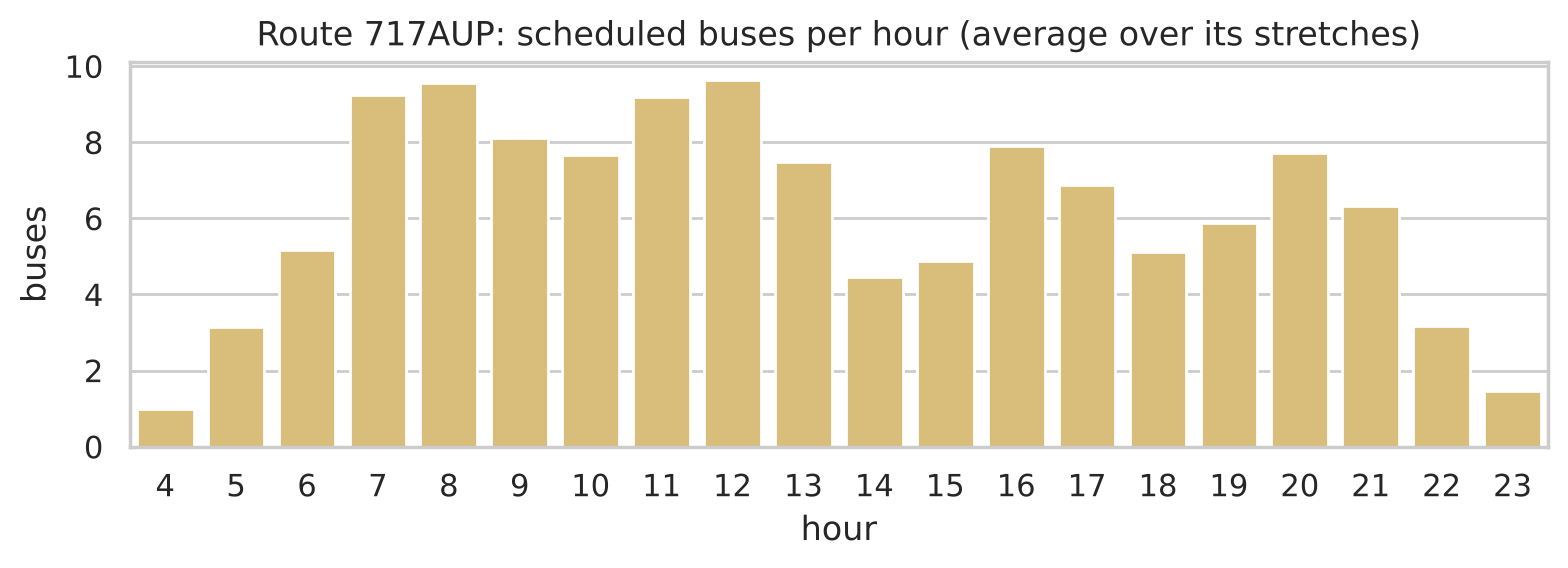

In [6]:
r_n = patterns[patterns.route == top_route].route_n.iloc[0]
s = supply[supply.route_n == r_n].groupby("hour").n_sched.mean()
plt.figure(figsize=(8, 3)); sns.barplot(x=s.index, y=s.values, color="#e9c46a")
plt.title(f"Route {top_route}: scheduled buses per hour (average over its stretches)"); plt.ylabel("buses"); plt.tight_layout(); plt.show()

> **Assumption (say it out loud in the presentation):** the GTFS has one service calendar for **all 7 days**, so weekends show the same schedule as weekdays.
> In reality weekend service is thinner. If weekend buses are really fewer, our weekend crowd index is slightly **too low**.

## 3. Save the timetable tables to the database

In [7]:
engine = db.get_engine()
db.save_table(patterns, "route_patterns", engine, index_cols=["route_n"])
db.save_table(hourly, "route_hourly", engine, index_cols=["route_n"])
db.save_table(supply, "route_supply", engine, index_cols=["route_n"])
meta = pd.read_csv(config.GTFS_DIR / "routes.txt", dtype=str, keep_default_na=False)[["route_id", "agency_id", "route_desc"]]
db.save_table(meta, "route_meta", engine)          # official route descriptions + agency (DTC / DIMTS) for the API
db.describe_database(engine)

,table,rows,columns
0,crowd_global,12,"daytype, band, pax_sum, n_sched, g_idx"
1,crowd_hourly_cells,1190724,"route_n, daytype, hour, pos, n_sched, pax_sum,..."
2,crowd_route_level,20744,"route_n, daytype, band, pax_sum, n_tickets, n_..."
3,crowd_segments,627324,"route_n, daytype, band, pos, pax_sum, n_ticket..."
4,crowd_table,1770724,"route_n, daytype, hour, pos, from_stop_id, to_..."
5,ml_classification_cv,3,"model, mean_macro_F1, std, folds"
6,ml_classification_results,16,"model, split, accuracy, balanced_acc, macro_F1..."
7,ml_regression_cv,4,"model, mean_R2, std_R2, folds"
8,ml_regression_results,20,"model, split, train_R2, test_R2, test_MAE, tes..."
9,route_attrs,1971,"route_n, route, is_ac, n_tickets"


## 4. Match ticket stop names to GTFS stops
Ticket names are typed by conductors / apps. The same stop can appear as `Zakhira Fly Over`, `Zakhira Flyover`, `Zakira Flyover`...

For every distinct *(route, name)* pair we try, in order, and **stop at the first that works**:

1. `exact_route` - same text (after lower-casing and expanding short forms like *Sec* -> *sector*) as a stop **on that route**
2. `fuzzy_route` - very similar text on that route (fuzzy score >= 86 out of 100)
3. `partial_route` - the ticket name is a *part* of a stop name on that route (`Mahipal Pur` -> `Mahipal Pur Village`)
4. `fuzzy_global_offroute` - a near-identical stop elsewhere in Delhi (strict). Not on the route, so it cannot be used for the journey.
5. `none` - give up.

We always look **inside the route first**, which keeps wrong matches rare.

In [8]:
# SQL does the counting: how often does each (route, stop name) pair appear, as start or end of a ticket?
name_counts = db.query('''
    SELECT route_raw, start_name AS name, COUNT(*) AS n FROM tickets GROUP BY route_raw, start_name
    UNION ALL
    SELECT route_raw, end_name AS name, COUNT(*) AS n FROM tickets GROUP BY route_raw, end_name
''', engine)
print(f"{len(name_counts):,} (route, name) rows -> matching them takes about 20-40 seconds")
stop_map = gtfs.match_stop_names(name_counts, patterns)
stop_map.head()

115,261 (route, name) rows -> matching them takes about 20-40 seconds


,route_raw,route_n,name,name_n,gtfs_name_n,score,method,n_uses
0,0114(NS)UP,114(NS)UP,Alpana Cinema,alpana cinema,alpana cinema model town mtr station,100.0,partial_route,1
1,0114(NS)UP,114(NS)UP,Ashok Vihar Crossing,ashok vihar crossing,ashok vihar crossing,100.0,exact_route,1
2,0114(NS)UP,114(NS)UP,Avantika Xing,avantika xing,avantika xing,100.0,exact_route,1
3,0114(NS)UP,114(NS)UP,Azadpur,azadpur,azadpur terminal,100.0,partial_route,6
4,0114(NS)UP,114(NS)UP,Begam Pur,begam pur,NaN,0.0,none,6


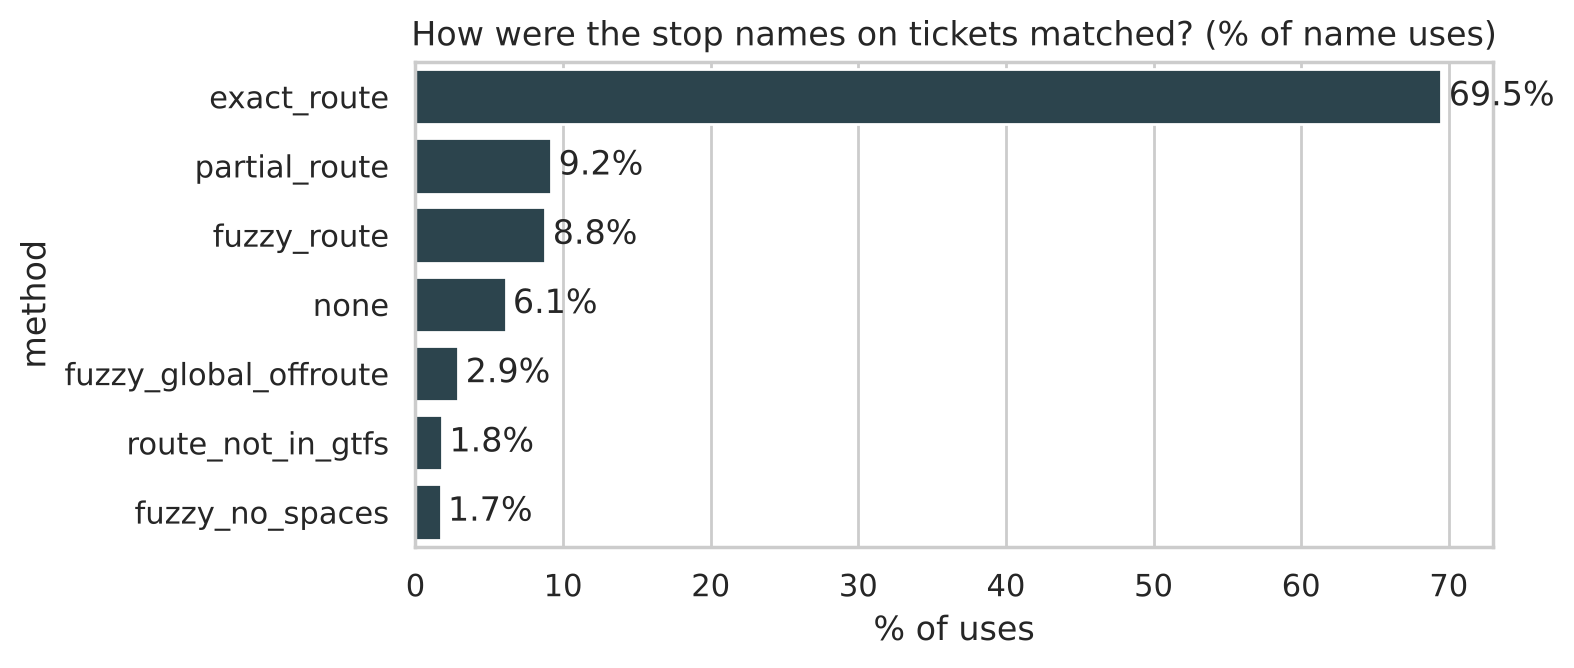

Matched to a stop ON the route: 87.5% of name uses


In [9]:
share = stop_map.groupby("method").n_uses.sum().sort_values(ascending=False)
share = (share / share.sum() * 100).round(1)
plt.figure(figsize=(8, 3.5)); sns.barplot(y=share.index, x=share.values, color="#264653")
for i, v in enumerate(share.values): plt.text(v + 0.5, i, f"{v}%", va="center")
plt.title("How were the stop names on tickets matched? (% of name uses)"); plt.xlabel("% of uses"); plt.tight_layout()
plt.savefig(config.FIG / "02_match_methods.png", dpi=130); plt.show()
usable = share[["exact_route", "fuzzy_route", "partial_route"]].sum()
print(f"Matched to a stop ON the route: {usable:.1f}% of name uses")

**Two honest notes**
- *"Matched"* means "found a stop with a very similar name on the route". It does **not** prove it is the right stop. In particular `partial_route`
  can pick the wrong one when a route has several stops that share words. The audit below lets you check by eye.
- Blank names, and routes missing from the GTFS (`route_not_in_gtfs`) cannot be matched at all.

In [10]:
# Manual audit: 15 random partial matches, weighted by how often they occur. Do they look right?
audit = stop_map[stop_map.method == "partial_route"].sample(15, weights="n_uses", random_state=config.RANDOM_STATE)
audit[["route_raw", "name", "gtfs_name_n", "score", "n_uses"]].reset_index(drop=True)

,route_raw,name,gtfs_name_n,score,n_uses
0,502DOWN,Shahjahan Road,shahjahan road upsc,100.0,383
1,D-9101UP,Dwarka Flyover Railway Crossing,maharaja agrasen hospital dwarka dwarka crossing,100.0,757
2,882ADOWN,Narela Old Mandi,old anaj mandi narela mandi,100.0,8
3,741DOWN,Uttam Nagar Terminal / A1 Janakpuri,a1 janakpuri,100.0,293
4,261UP,Dr. Ambedkar Stadium / Delhi Gate,delhi gate ambedkar stadium terminal,100.0,52
5,144UP,Singhu Border,singhu border gt road,100.0,1812
6,982UP,Ludlow Castle School,ludlow castle,100.0,13
7,761DOWN,Mangla Puri,mangla puri xing,100.0,1595
8,85UP,Laxmi Nagar Xing,laxmi nagar x ing laxmi nagar,100.0,988
9,114EXTDOWN,Karala,karala school,100.0,16


In [11]:
# What is still unmatched? (the biggest cases first)
unmatched = stop_map[stop_map.method.isin(["none", "route_not_in_gtfs"])].sort_values("n_uses", ascending=False)
unmatched.to_csv(config.OUT / "02_unmatched_names.csv", index=False)
print(f"{len(unmatched):,} unmatched (route, name) pairs saved to outputs/02_unmatched_names.csv")
unmatched[["route_raw", "name", "method", "n_uses"]].head(10)

9,011 unmatched (route, name) pairs saved to outputs/02_unmatched_names.csv


,route_raw,name,method,n_uses
25835,502DOWN,S.J. Hospital,none,2643
25874,502UP,S.J. Hospital,none,1892
48481,8DOWN,Jaitpur Xing,none,1682
29911,578UP,Dhansa Stand Najaf Garh,none,1546
29285,567BSTLUP,Nangloi (Najafgarh Road),route_not_in_gtfs,1495
29887,578DOWN,S.J. Terminal,none,1449
61740,D-034UP,Reddison Hotel Mahipal Pur / Rang Puri (Nh8 Ci...,none,1429
45688,85UP,Government Model School,none,1363
45719,85UP,Shadi Pur Metro Station,none,1339
65275,D-9101DOWN,Aerocity,none,1307


Most unmatched names are **localities** ("Mahipal Pur", "Badarpur") that the route list only has in a longer form such as "Mahipalpur Village" or "Badarpur Border", or stops that
exist on a different trip variant than the one we keep. Adding a Hindi/English alias table would help - listed as future work.

In [12]:
db.save_table(stop_map, "stop_map", engine, index_cols=["route_raw"])
import json
report = {"name_pairs": int(len(stop_map)), "share_of_uses_pct": share.to_dict(), "matched_on_route_pct": round(float(usable), 1)}
(config.OUT / "02_match_report.json").write_text(json.dumps(report, indent=2)); report

{'name_pairs': 69640,
 'share_of_uses_pct': {'exact_route': 69.5,
  'partial_route': 9.2,
  'fuzzy_route': 8.8,
  'none': 6.1,
  'fuzzy_global_offroute': 2.9,
  'route_not_in_gtfs': 1.8,
  'fuzzy_no_spaces': 1.7},
 'matched_on_route_pct': 87.5}

**Next:** `03_crowd_index.ipynb` - place every ticket on its route, count passengers per stretch, divide by buses, and build the crowd table.